# Isotonic regression: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/miscellaneous/plot_isotonic_regression.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/miscellaneous/plot_isotonic_regression.html)).
It is the only gallery example that imports `sklearn.isotonic`.

**Scenario:** `IsotonicRegression(out_of_bounds="clip").fit_transform(x, y)` on 100 noisy points with a
logarithmic trend, a `LinearRegression` for comparison, and `predict` on `np.linspace(-10, 110, 1000)`
(which extrapolates by clipping), plus the fitted `X_thresholds_`/`y_thresholds_`.

**Additions beyond the example** (section 2), so that one notebook exercises the implemented public API:
`increasing="auto"`, `y_min`/`y_max` with zero and positive `sample_weight`, `out_of_bounds="nan"` and `"raise"`,
`f_`, weighted `score`, the `isotonic_regression` and `check_increasing` helpers, `set_params` then refit,
`clone`, Float32, one-column 2-D input, and `cross_val_score` / `GridSearchCV` composition (section 3).

**Adaptations:**
- Data is generated in Python exactly as in the example and shared as `.npy`; Mojo converts the 1-D NDArrays to
  `List[Float64]`, because `moxie.isotonic` takes List inputs (documented in `docs/isotonic/api.md`).
- The Mojo side saves lists through `save_floats`; Float32 results are widened exactly to Float64 for saving.
- Plots are drawn twice from the same data: once with sklearn's outputs, once with Moxie's.

**Determinism:** the reference is deterministic (`check_random_state(0)`, no threading), so predictions and learned
attributes are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("isotonic/plot_isotonic_regression")

## 1. The official example

### scikit-learn (Python reference)

The example code, unchanged except for a smaller figure (`dpi=60`) and capturing the outputs.

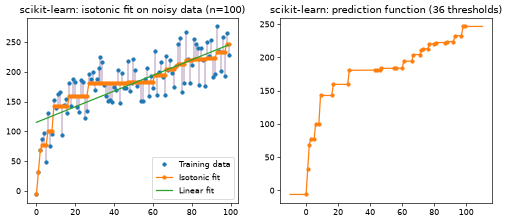

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LinearRegression
from sklearn.utils import check_random_state

n = 100
x = np.arange(n)
rs = check_random_state(0)
y = rs.randint(-50, 50, size=(n,)) + 50.0 * np.log1p(np.arange(n))

ir = IsotonicRegression(out_of_bounds="clip")
y_ = ir.fit_transform(x, y)

lr = LinearRegression()
lr.fit(x[:, np.newaxis], y)  # x needs to be 2d for LinearRegression

x_test = np.linspace(-10, 110, 1000)


def plot(title, y_fit, lr_pred, test_pred, X_thr, y_thr):
    segments = [[[i, y[i]], [i, y_fit[i]]] for i in range(n)]
    lc = LineCollection(segments, zorder=0)
    lc.set_array(np.ones(len(y)))
    lc.set_linewidths(np.full(n, 0.5))
    fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(10, 4), dpi=60)
    ax0.plot(x, y, "C0.", markersize=8)
    ax0.plot(x, y_fit, "C1.-", markersize=8)
    ax0.plot(x, lr_pred, "C2-")
    ax0.add_collection(lc)
    ax0.legend(("Training data", "Isotonic fit", "Linear fit"), loc="lower right")
    ax0.set_title(f"{title}: isotonic fit on noisy data (n={n})")
    ax1.plot(x_test, test_pred, "C1-")
    ax1.plot(X_thr, y_thr, "C1.", markersize=8)
    ax1.set_title(f"{title}: prediction function ({len(X_thr)} thresholds)")
    plt.show()


sk = dict(y_=y_, lr_pred=lr.predict(x[:, np.newaxis]), predict_test=ir.predict(x_test),
          X_thresholds_=ir.X_thresholds_, y_thresholds_=ir.y_thresholds_,
          domain=np.array([ir.X_min_, ir.X_max_]), increasing_=ir.increasing_)
plot("scikit-learn", sk["y_"], sk["lr_pred"], sk["predict_test"], sk["X_thresholds_"], sk["y_thresholds_"])
nb.share(x=x.astype(float), y=y, x_2d=x[:, np.newaxis].astype(float), x_test=x_test)

### Moxie (native Mojo)

In [3]:
%%mojo example
from numojo import NDArray
from moxie.isotonic import IsotonicRegression
from moxie.linear_model import LinearRegression
from moxie_nb_io import load, save, save_floats


def to_list(a: NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(a.size):
        out.append(a.unsafe_get(i))
    return out^


def main() raises:
    var x = to_list(load("x"))
    var y = to_list(load("y"))
    var x_test = to_list(load("x_test"))
    var ir = IsotonicRegression(out_of_bounds="clip")
    var y_ = ir.fit_transform(x, y.copy())
    var lr = LinearRegression()
    _ = lr.fit(load("x_2d"), load("y"))
    save_floats("y_", y_)
    save("lr_pred", lr.predict(load("x_2d")))
    save_floats("predict_test", ir.predict(x_test))
    save_floats("X_thresholds_", ir.X_thresholds_)
    save_floats("y_thresholds_", ir.y_thresholds_)
    save_floats("domain", [ir.X_min_, ir.X_max_])
    save_floats("increasing_", [1.0 if ir.increasing_ else 0.0])
    print("thresholds:", len(ir.X_thresholds_), " increasing_:", ir.increasing_)

thresholds: 36  increasing_: True


### Side by side and parity

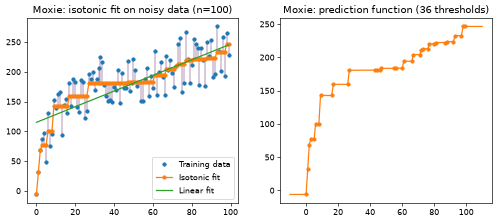

True

In [4]:
mx = nb.results["example"]
plot("Moxie", mx["y_"], mx["lr_pred"], mx["predict_test"], mx["X_thresholds_"], mx["y_thresholds_"])
moxie_nb.side_by_side(sklearn_X_thresholds=sk["X_thresholds_"], moxie_X_thresholds=mx["X_thresholds_"])
moxie_nb.side_by_side(sklearn_y_thresholds=sk["y_thresholds_"], moxie_y_thresholds=mx["y_thresholds_"])
pava = "PAVA pools blocks in a different reduction order than SciPy's solver; Float64 roundoff only (as the family parity gate)"
nb.compare("X_thresholds_", sk["X_thresholds_"], mx["X_thresholds_"], exact=True)
nb.compare("y_thresholds_", sk["y_thresholds_"], mx["y_thresholds_"], rtol=1e-12, atol=1e-12, reason=pava)
nb.compare("fit_transform", sk["y_"], mx["y_"], rtol=1e-12, atol=1e-12, reason=pava)
nb.compare("predict(x_test), clip", sk["predict_test"], mx["predict_test"], rtol=1e-12, atol=1e-12,
           reason=pava + "; interpolation formula matches interp1d up to one rounding")
nb.compare("X_min_, X_max_", sk["domain"], mx["domain"], exact=True)
nb.compare("increasing_", np.array([float(sk["increasing_"])]), mx["increasing_"], exact=True)
nb.compare("LinearRegression.predict", sk["lr_pred"], mx["lr_pred"], rtol=1e-10, atol=1e-9,
           reason="lstsq-based solver differs from SciPy's LAPACK path in the last bits")

## 2. The rest of the public API on the same data

Not part of the gallery example: auto direction, bounds, weights (with zero weights, which the estimator drops),
NaN/raise out-of-bounds handling, `f_`, weighted `score`, the two module-level helpers, `set_params` + refit,
`clone`, Float32 and one-column 2-D input.

In [5]:
from sklearn.base import clone
from sklearn.isotonic import check_increasing, isotonic_regression

w = np.random.RandomState(1).uniform(0.1, 3.0, size=n)
w[::17] = 0.0
x_hold = np.linspace(1, 99, 50)  # w[0] == 0, so the weighted domain starts at 1
y_hold = 50.0 * np.log1p(x_hold)
w_hold = np.linspace(0.5, 2.0, 50)
x_inner = np.linspace(0, 99, 37)
ref = {}

auto = IsotonicRegression(increasing="auto").fit(x, -y)
ref["auto_increasing"] = [float(auto.increasing_)]
ref["auto_X_thr"], ref["auto_y_thr"] = auto.X_thresholds_, auto.y_thresholds_

bounded = IsotonicRegression(y_min=20.0, y_max=150.0).fit(x, y, sample_weight=w)
ref["bounded_X_thr"], ref["bounded_y_thr"] = bounded.X_thresholds_, bounded.y_thresholds_
ref["bounded_pred_nan"] = bounded.predict(x_test)          # NaN outside [X_min_, X_max_]
ref["bounded_score"] = [bounded.score(x_hold, y_hold, sample_weight=w_hold)]
ref["f_"] = bounded.f_(x_inner)
ref["iso_reg"] = isotonic_regression(y, sample_weight=np.where(w > 0, w, 1.0), y_min=20.0, y_max=150.0)
ref["iso_dec"] = isotonic_regression(y, increasing=False)
ref["check_inc"] = [float(check_increasing(x, y)), float(check_increasing(x, -y))]

bounded.set_params(increasing=False, out_of_bounds="clip").fit(x, y)
ref["refit_X_thr"], ref["refit_y_thr"] = bounded.X_thresholds_, bounded.y_thresholds_
ref["refit_pred"] = bounded.predict(x_test)
print("clone of a fitted model is unfitted:", not hasattr(clone(bounded), "X_thresholds_"))

m32 = IsotonicRegression(out_of_bounds="clip").fit(x.astype(np.float32), y.astype(np.float32))
ref["f32_X_thr"], ref["f32_y_thr"] = m32.X_thresholds_, m32.y_thresholds_
ref["f32_pred"] = m32.predict(x_test.astype(np.float32))
print("Float32 dtypes:", m32.X_thresholds_.dtype, m32.predict(x_test.astype(np.float32)).dtype)

col = IsotonicRegression().fit(x[:, None], y)
ref["column_pred"] = col.predict(x_inner[:, None])

strict = IsotonicRegression(out_of_bounds="raise").fit(x, y)
try:
    strict.predict(x_test)
except ValueError as e:
    print("raise mode:", e)
nb.share(w=w, x_hold=x_hold, y_hold=y_hold, w_hold=w_hold, x_inner=x_inner, iso_w=np.where(w > 0, w, 1.0))

clone of a fitted model is unfitted: True
Float32 dtypes: float32 float32
raise mode: A value (-10.0) in x_new is below the interpolation range's minimum value (0.0).


In [6]:
%%mojo api_tour
from numojo import NDArray
from moxie.base import clone
from moxie.isotonic import IsotonicRegression, Increasing, isotonic_regression, check_increasing
from moxie_nb_io import load, save_floats


def to_list(a: NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(a.size):
        out.append(a.unsafe_get(i))
    return out^


def wide(values: List[Float32]) -> List[Float64]:
    var out = List[Float64]()
    for v in values:
        out.append(Float64(v))
    return out^


def narrow(values: List[Float64]) -> List[Float32]:
    var out = List[Float32]()
    for v in values:
        out.append(Float32(v))
    return out^


def flag(value: Bool) -> Float64:
    return 1.0 if value else 0.0


def main() raises:
    var x = to_list(load("x"))
    var y = to_list(load("y"))
    var w = to_list(load("w"))
    var x_test = to_list(load("x_test"))
    var x_inner = to_list(load("x_inner"))
    var neg = List[Float64]()
    for v in y:
        neg.append(-v)

    var auto = IsotonicRegression(increasing="auto")
    _ = auto.fit(x, neg)
    save_floats("auto_increasing", [flag(auto.increasing_)])
    save_floats("auto_X_thr", auto.X_thresholds_)
    save_floats("auto_y_thr", auto.y_thresholds_)

    var bounded = IsotonicRegression(y_min=20.0, y_max=150.0)
    _ = bounded.fit(x, y, sample_weight=w)
    save_floats("bounded_X_thr", bounded.X_thresholds_)
    save_floats("bounded_y_thr", bounded.y_thresholds_)
    save_floats("bounded_pred_nan", bounded.predict(x_test))
    save_floats("bounded_score", [bounded.score(to_list(load("x_hold")), to_list(load("y_hold")),
                                                to_list(load("w_hold")))])
    save_floats("f_", bounded.f_(x_inner))
    save_floats("iso_reg", isotonic_regression(y, sample_weight=to_list(load("iso_w")), y_min=20.0, y_max=150.0))
    save_floats("iso_dec", isotonic_regression(y, increasing=False))
    save_floats("check_inc", [flag(check_increasing(x, y)), flag(check_increasing(x, neg))])

    _ = bounded.set_params(increasing=Increasing(False), out_of_bounds=String("clip")).fit(x, y)
    save_floats("refit_X_thr", bounded.X_thresholds_)
    save_floats("refit_y_thr", bounded.y_thresholds_)
    save_floats("refit_pred", bounded.predict(x_test))
    print("clone of a fitted model is unfitted:", not clone(bounded).__sklearn_is_fitted__())

    var m32 = IsotonicRegression[DType.float32](out_of_bounds="clip")
    _ = m32.fit(narrow(x), narrow(y))
    save_floats("f32_X_thr", wide(m32.X_thresholds_))
    save_floats("f32_y_thr", wide(m32.y_thresholds_))
    save_floats("f32_pred", wide(m32.predict(narrow(x_test))))

    var rows = List[List[Float64]]()
    for v in x:
        rows.append([v])
    var inner_rows = List[List[Float64]]()
    for v in x_inner:
        inner_rows.append([v])
    var col = IsotonicRegression()
    _ = col.fit(rows, y)
    save_floats("column_pred", col.predict(inner_rows))

    var strict = IsotonicRegression(out_of_bounds="raise")
    _ = strict.fit(x, y)
    try:
        _ = strict.predict(x_test)
        print("raise mode: no error (unexpected)")
    except e:
        print("raise mode:", e)

clone of a fitted model is unfitted: True
raise mode: ValueError: input is outside the interpolation range


In [7]:
mx = nb.results["api_tour"]
moxie_nb.side_by_side(sklearn_bounded_y_thr=ref["bounded_y_thr"], moxie_bounded_y_thr=mx["bounded_y_thr"])
for name in ["auto_increasing", "check_inc", "auto_X_thr", "bounded_X_thr", "refit_X_thr"]:
    nb.compare(name, np.asarray(ref[name], float), mx[name], exact=True)
for name in ["auto_y_thr", "bounded_y_thr", "bounded_pred_nan", "f_", "iso_reg", "iso_dec",
             "refit_y_thr", "refit_pred", "column_pred"]:
    nb.compare(name, ref[name], mx[name], rtol=1e-12, atol=1e-12, reason=pava + "; NaN positions must match")
nb.compare("bounded_score (weighted R2)", ref["bounded_score"], mx["bounded_score"], rtol=1e-12, atol=1e-12,
           reason="Float64 weighted sums in a different order than r2_score")
nb.compare("Float32 X_thresholds_", ref["f32_X_thr"], mx["f32_X_thr"], exact=True)
for name in ["f32_y_thr", "f32_pred"]:
    nb.compare(name, ref[name], mx[name], rtol=2e-6, atol=2e-6,
               reason="Float32 rounding and reduction order (family parity tolerance); one Float32 ulp near |y|=250 is 1.5e-5, i.e. 6e-8 relative")
nb.note("raise-mode error type", "ADAPTED",
        "Moxie raises Error('ValueError: input is outside the interpolation range'); sklearn raises SciPy's ValueError")
nb.note("f_", "ADAPTED", "f_ is a method on the estimator, not a stored interp1d callable (docs/isotonic/api.md)")
nb.note("List inputs", "ADAPTED", "1-D data passes as List[Float64]/List[Float32], one-column 2-D as List[List[...]]")

## 3. Composition: clone, cross-validation, search, Pipeline

scikit-learn users run `cross_val_score(IsotonicRegression(out_of_bounds="clip"), x, y)` and tune it with
`GridSearchCV` directly on 1-D `x`. Moxie's typed model_selection needs a family adapter that slices the inputs
(`CVAdapter` / `SearchAdapter`); isotonic ships none, so the cell below defines one for `List[Float64]`
(see #3 part 3 for the missing built-in adapters). `KFold(5)` without shuffling gives identical folds on both sides.

In [8]:
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

sk_cv = cross_val_score(IsotonicRegression(out_of_bounds="clip"), x, y, cv=KFold(5))
y_maxes = [100.0, 150.0, 200.0, 1000.0]
search = GridSearchCV(IsotonicRegression(out_of_bounds="clip"), {"y_max": y_maxes}, cv=KFold(5)).fit(x, y)
sk_search = dict(mean=search.cv_results_["mean_test_score"], best=[search.best_params_["y_max"], search.best_score_],
                 y_thr=search.best_estimator_.y_thresholds_)
print("cross_val_score:", np.round(sk_cv, 4))
print("best y_max:", search.best_params_["y_max"], "best score:", round(search.best_score_, 4))
nb.share(y_maxes=np.asarray(y_maxes))

cross_val_score: [-5.589e-01 -1.610e-02 -1.000e-04  4.830e-02 -1.880e-02]
best y_max: 1000.0 best score: -0.1091


In [9]:
%%mojo cv_search
from numojo import NDArray
from moxie.isotonic import IsotonicRegression
from moxie.model_selection import (GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer,
                                   cross_val_score)
from moxie_nb_io import load, save, save_floats

comptime Values = List[Float64]


def to_list(a: NDArray[DType.float64]) raises -> Values:
    var out = Values()
    for i in range(a.size):
        out.append(a.unsafe_get(i))
    return out^


def take(values: Values, rows: IndexArray) raises -> Values:
    var out = Values()
    for i in range(rows.size):
        out.append(values[Int(rows.unsafe_get(i))])
    return out^


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct IsotonicR2(SearchScorer):
    # sklearn's default regressor scorer: estimator.score (R2).
    comptime Estimator = IsotonicRegression[]
    comptime Input = Values
    comptime Target = Values
    comptime Metadata = Optional[Values]

    def __init__(out self):
        pass

    def score(self, estimator: IsotonicRegression[], X: Values, y: Values, metadata: Optional[Values]) raises -> Float64:
        return estimator.score(X, y)


struct IsotonicRows(SearchAdapter):
    comptime Scorer = IsotonicR2
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Values, y: Values) raises -> Int:
        return len(y)

    def input_rows(self, X: Values, rows: IndexArray, train: IndexArray) raises -> Values:
        return take(X, rows)

    def target_rows(self, y: Values, rows: IndexArray) raises -> Values:
        return take(y, rows)

    def metadata_rows(self, metadata: Optional[Values], rows: IndexArray) raises -> Optional[Values]:
        return None

    def fit(self, mut estimator: IsotonicRegression[], X: Values, y: Values, metadata: Optional[Values]) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: IsotonicRegression[], params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key != "y_max":
                raise Error("ValueError: this adapter tunes only y_max")
        _ = estimator.set_params(y_max=params["y_max"])

    def default_scorer(self) raises -> IsotonicR2:
        return IsotonicR2()

    def default_cv(self, X: Values, y: Values) raises -> List[IndexSplit]:
        return kfold(len(y))


def main() raises:
    var x = to_list(load("x"))
    var y = to_list(load("y"))
    var model = IsotonicRegression(out_of_bounds="clip")
    save("cv_scores", cross_val_score[IsotonicRows](model, x, y, IsotonicRows(), IsotonicR2(), kfold(len(y)),
                                                     None, None))
    var grid = Dict[String, List[Float64]]()
    grid["y_max"] = to_list(load("y_maxes"))
    var search = GridSearchCV[IsotonicRows](IsotonicRegression(out_of_bounds="clip"), grid, IsotonicRows(),
                                            cv=kfold(len(y)))
    search.fit(x, y, None, None)
    save("search_mean", search.cv_results_().mean_test_score)
    save_floats("search_best", [search.best_params_()["y_max"], search.best_score_()])
    save_floats("search_y_thr", search.best_estimator_().y_thresholds_)

In [10]:
mx = nb.results["cv_search"]
moxie_nb.side_by_side(sklearn_cv=sk_cv, moxie_cv=mx["cv_scores"])
nb.compare("cross_val_score (KFold 5)", sk_cv, mx["cv_scores"], rtol=1e-12, atol=1e-12,
           reason=pava + "; R2 sums in Float64")
nb.compare("GridSearchCV mean_test_score", sk_search["mean"], mx["search_mean"][:, 0], rtol=1e-12, atol=1e-12,
           reason="same folds and scorer; column 0 is the single metric (model_selection layout)")
nb.compare("GridSearchCV best y_max, best_score_", sk_search["best"], mx["search_best"], rtol=1e-12, atol=1e-12,
           reason="best_score_ is a mean of R2 values")
nb.compare("best_estimator_.y_thresholds_", sk_search["y_thr"], mx["search_y_thr"], rtol=1e-12, atol=1e-12,
           reason=pava)
nb.note("CV/search adapter", "ADAPTED", "isotonic ships no CVAdapter/SearchAdapter; the notebook defines one over List[Float64] (#3 part 3)")

In scikit-learn `make_pipeline(StandardScaler(), IsotonicRegression()).fit(x[:, None], y)` works, because the
scaler returns a one-column array and `IsotonicRegression` accepts `(n, 1)` input. Moxie transformers produce
`NDArray`, while `IsotonicRegression.Input` is `List[Scalar[dtype]]`. The typed Pipeline takes its `Target` from the final step, so `fit` already fails to
compile on the NDArray target (`cannot be converted from 'NDArray' to ref 'Pipeline[StandardScaler,
IsotonicRegression].Target'`); with a List target the scaler's NDArray output still cannot feed the List `Input`.
Passing the NDArrays directly to `IsotonicRegression.fit` fails with `no matching method in call to 'fit'`.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sk_pipe = make_pipeline(StandardScaler(), IsotonicRegression(out_of_bounds="clip")).fit(x[:, None], y)
sk_pipe_pred = sk_pipe.predict(x_test[:, None])
print("sklearn pipeline thresholds:", len(sk_pipe[-1].X_thresholds_))

sklearn pipeline thresholds: 36


In [12]:
%%mojo pipeline_scaler_isotonic --expect-fail
from moxie.isotonic import IsotonicRegression
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save


def main() raises:
    var pipe = make_pipeline(StandardScaler(), IsotonicRegression(out_of_bounds="clip"))
    _ = pipe.fit(load("x_2d"), load("y"))
    save("pred", pipe.predict(load("x_2d")))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/pipeline_scaler_isotonic.mojo:9:36: error: invalid call to 'fit': value passed to 'y' cannot be converted from 'NDArray' to ref 'Pipeline[StandardScaler, IsotonicRegression].Target'
    _ = pipe.fit(load("x_2d"), load("y"))
        ~~~~~~~~               ~~~~^~~~~
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/pipeline_scaler_isotonic.mojo:9:36: note: cannot bind an RValue to a reference
    _ = pipe.fit(load("x_2d"), load("y"))
                                   ^
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/pipeline_scaler_isotonic.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/pipeline.mojo:6:
Imported from /home/strg

In [13]:
%%mojo ndarray_input --expect-fail
from moxie.isotonic import IsotonicRegression
from moxie_nb_io import load


def main() raises:
    var model = IsotonicRegression(out_of_bounds="clip")
    _ = model.fit(load("x"), load("y"))
    print(model.predict(load("x_test")))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/ndarray_input.mojo:7:14: error: no matching method in call to 'fit'
    _ = model.fit(load("x"), load("y"))
        ~~~~~^~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/ndarray_input.mojo:1:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/isotonic.mojo:322:9: note: candidate not viable: value passed to 'X' cannot be converted from 'NDArray' to ref 'List[Float64]'
    def fit[origin: MutOrigin, x_origin: ImmOrigin, y_origin: ImmOrigin](ref[origin] self, ref[x_origin] X: Self.Input, ref[y_origin] y: Self.Target) raises -> ref[self] Self:
        ^
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/isotonic/plot_isotonic_regression/ndarray_input.mojo:7:23: note: cannot bind an RVal

In [14]:
nb.note("make_pipeline(StandardScaler(), IsotonicRegression())", "GAP",
        "Moxie transformers output NDArray; IsotonicRegression.Input is List, so the typed Pipeline fails to compile")
nb.note("NDArray input", "GAP", "fit/predict/transform/score take List or List[List] only; NDArray needs manual conversion")
nb.note("pickle / persistence", "GAP", "no ModelSchema for IsotonicRegression (opt-in per docs/serialization.md)")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
X_thresholds_,PASS,"(36,)","(36,)",,,exact,0 mismatches,
y_thresholds_,PASS,"(36,)","(36,)",2.84e-14,1.57e-16,"rtol=1e-12, atol=1e-12",,PAVA pools blocks in a different reduction order than SciPy's solver; Float64 roundoff only (as the family parity gate)
fit_transform,PASS,"(100,)","(100,)",2.84e-14,1.57e-16,"rtol=1e-12, atol=1e-12",,PAVA pools blocks in a different reduction order than SciPy's solver; Float64 roundoff only (as the family parity gate)
"predict(x_test), clip",PASS,"(1000,)","(1000,)",2.84e-14,1.75e-16,"rtol=1e-12, atol=1e-12",,PAVA pools blocks in a different reduction order than SciPy's solver; Float64 roundoff only (as the family parity gate); interpolation formula matches interp1d up to one rounding
"X_min_, X_max_",PASS,"(2,)","(2,)",,,exact,0 mismatches,
increasing_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
LinearRegression.predict,PASS,"(100,)","(100,)",5.68e-14,3.12e-16,"rtol=1e-10, atol=1e-09",,lstsq-based solver differs from SciPy's LAPACK path in the last bits
auto_increasing,PASS,"(1,)","(1,)",,,exact,0 mismatches,
check_inc,PASS,"(2,)","(2,)",,,exact,0 mismatches,
auto_X_thr,PASS,"(36,)","(36,)",,,exact,0 mismatches,
